# 05 · Risk: Value-at-Risk and Expected Shortfall

What are the one-day VaR and ES of the US stock market, with their uncertainty, how much of the gap with the Gaussian answer comes from heavy tails and how much from not knowing the parameters, and how should the probability of a rare loss be computed?

| Reads | Produces | Running time |
|---|---|---|
| `results/draws_student_t.npy`, `results/draws_gaussian.npy` (notebook 04)<br>`data/returns.csv`, `tools.py` | `../report/tables/risk.tex` (report, Section 6.2), `../report/figures/risk.pdf` (report, appendix)<br>`../report/figures/rare_event.pdf` (report, Section 6.3), `../report/tables/rare_event.tex`, `../report/tables/rare_es.tex` (report, appendix)<br>`../report/tables/risk_mcse.tex` (report, appendix) | about 30 seconds |

01 Data → 02 Model and sampler → 03 Validation → 04 Posterior → **05 Risk** → 06 Checks

In [1]:
# Setup: libraries, our shared functions and the constants of this notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from tools import (COLOR_DATA, COLOR_GAUSS, COLOR_OTHER, COLOR_T, es_gauss, es_t, predictive_var_es,
                   save_figure, save_table, set_style, tail_t, var_gauss, var_t)

SEED = 2026
rng = np.random.default_rng(SEED)
LEVELS = [0.975, 0.99, 0.999]  # 97.5%: the Basel level for ES; 99%: our headline; 99.9%: extreme
N_BATCHES = 10                 # batches per chain for the Monte Carlo errors (batch means)

# Rare event study (Section 4)
THRESHOLDS = [0.05, 0.10, 0.20]  # one-day losses beyond 5%, 10% and 20%
N_DRAWS = 10_000                 # draws per estimate
N_REPEATS = 500                  # repetitions of each estimator
PARETO_INDEX = 2.0               # tail index of the importance sampling proposal

# Posterior draws of notebook 04 (4 chains x 18,000): (mu, sigma, nu) and, for the Gaussian, (mu, s)
theta_t = np.load("results/draws_student_t.npy")
theta_g = np.load("results/draws_gaussian.npy")
losses = -pd.read_csv("data/returns.csv")["y"].to_numpy()  # the observed daily losses L_t = -y_t
set_style()

In [2]:
def batches(draws):
    """Cut each chain into N_BATCHES consecutive batches (batch means, Chapter 5 lab, Section 4).

    draws: array (chains, iterations, ...). Returns the list of batches. Each batch (1,800 draws) is
    far longer than the autocorrelation time (about 10 iterations), so the batches are nearly independent.
    """
    length = draws.shape[1] // N_BATCHES
    batch_list = []
    for chain in draws:
        for b in range(N_BATCHES):
            batch_list.append(chain[b * length:(b + 1) * length])
    return batch_list


def batch_se(values):
    """Monte Carlo standard error of a statistic from its values on the batches: sd / sqrt(number)."""
    return np.std(values, ddof=1) / np.sqrt(len(values))

## 1. VaR and ES as functions of the parameters

For a loss $L = -y$ with $y = \mu + \sigma Z$ and $Z$ a standard Student-t with $\nu$ degrees of freedom, the VaR and ES at level $\alpha$ have closed forms. With $q_\alpha$ the $\alpha$-quantile of $Z$ and $f_\nu$ its density,

$$\text{VaR}_\alpha(\theta) = -\mu + \sigma\,q_\alpha, \qquad \text{ES}_\alpha(\theta) = -\mu + \sigma\,\frac{f_\nu(q_\alpha)}{1-\alpha}\cdot\frac{\nu + q_\alpha^2}{\nu - 1}$$

(derivation in the report's appendix). For the Gaussian, $\text{VaR}_\alpha = -\mu + s\,z_\alpha$ and $\text{ES}_\alpha = -\mu + s\,\varphi(z_\alpha)/(1-\alpha)$. Computed on every posterior draw, they give draws from the **posterior of VaR and ES**: a mean and a 95% credible interval for each. Each interval end is a Monte Carlo estimate too; we give its error by **batch means**.

> **[COURSE]** Posterior of a function of the parameters: Ch. 1, Sec. 1.2.2, Definition 1.4 (p. 16). Batch means: Chapter 5 lab, Section 4 (the ESS behind it: Ch. 5, Theorem 5.2, p. 64).

In [3]:
# Posterior of VaR(theta) and ES(theta), in %, for both models and the three levels
models = [("Student-t", theta_t, var_t, es_t), ("Gaussian", theta_g, var_gauss, es_gauss)]
rows = []
for model, theta, var_f, es_f in models:
    for alpha in LEVELS:
        for measure, f in [("VaR", var_f), ("ES", es_f)]:
            values = 100 * f(theta, alpha)  # shape (chains, draws)
            low_batches = [np.quantile(b, 0.025) for b in batches(values)]
            high_batches = [np.quantile(b, 0.975) for b in batches(values)]
            rows.append({"model": model, "measure": f"{measure} {100 * alpha:g}%",
                         "mean": values.mean(),
                         "2.5%": np.quantile(values, 0.025), "97.5%": np.quantile(values, 0.975),
                         "MCSE of the interval ends": max(batch_se(low_batches), batch_se(high_batches))})
posterior_risk = pd.DataFrame(rows).set_index(["model", "measure"])
posterior_risk.round(3)

mean    2.5%   97.5%  MCSE of the interval ends
model     measure                                                     
Student-t VaR 97.5%   2.364   2.253   2.484                      0.002
          ES 97.5%    4.206   3.836   4.641                      0.009
          VaR 99%     3.600   3.360   3.869                      0.005
          ES 99%      6.232   5.536   7.071                      0.016
          VaR 99.9%   9.549   8.317  11.021                      0.028
          ES 99.9%   16.180  13.321  19.788                      0.070
Gaussian  VaR 97.5%   2.402   2.344   2.462                      0.001
          ES 97.5%    2.873   2.807   2.941                      0.001
          VaR 99%     2.859   2.793   2.927                      0.001
          ES 99%      3.281   3.208   3.356                      0.001
          VaR 99.9%   3.810   3.728   3.896                      0.001
          ES 99.9%    4.156   4.067   4.247                      0.001

## 2. The predictive VaR and ES: one number that includes parameter uncertainty

A risk manager needs one number for tomorrow. The **posterior predictive** distribution of tomorrow's loss averages the model over our uncertainty about $\theta$,

$$p(\tilde L \mid y) = \int p(\tilde L \mid \theta)\,\pi(\theta \mid y)\,d\theta \;\approx\; \frac{1}{N}\sum_{i=1}^N p(\tilde L \mid \theta^{(i)}),$$

a mixture over the posterior draws. Its VaR solves $\frac1N\sum_i \Pr(\tilde L > v \mid \theta^{(i)}) = 1-\alpha$, and its ES is $\frac{1}{1-\alpha}\cdot\frac1N\sum_i \mathbb{E}[\tilde L\,\mathbf 1\{\tilde L > v\} \mid \theta^{(i)}]$. Both use the **exact** tail probability and tail mean given each $\theta^{(i)}$ (`predictive_var_es` in `tools.py`), instead of simulating losses: this is Rao–Blackwellization, which removes the noise of simulating $\tilde L$.

We compare it with the **plug-in** answer, which takes the posterior mean $\hat\theta$ as if it were the truth, and with the **historical** VaR and ES: the empirical quantile of the 5,031 observed losses and the mean of the losses beyond it.

> **[COURSE]** Posterior predictive and the two-stage simulation: Ch. 3, Sec. 3.1.2, Example 3.2 (p. 41). Rao–Blackwellization: Ch. 3, Sec. 3.5.2, Proposition 3.4 (p. 47).

In [4]:
# Plug-in (posterior mean), predictive and historical VaR and ES, in %
theta_hat_t = theta_t.reshape(-1, 3).mean(axis=0)
theta_hat_g = theta_g.reshape(-1, 2).mean(axis=0)
rows = []
for alpha in LEVELS:
    var_pred_t, es_pred_t = predictive_var_es(theta_t, alpha, "student_t")
    var_pred_g, es_pred_g = predictive_var_es(theta_g, alpha, "gaussian")
    var_hist = np.quantile(losses, alpha)
    es_hist = losses[losses >= var_hist].mean()
    rows.append({"measure": f"VaR {100 * alpha:g}%",
                 "Gaussian plug-in": var_gauss(theta_hat_g, alpha), "Gaussian predictive": var_pred_g,
                 "Student-t plug-in": var_t(theta_hat_t, alpha), "Student-t predictive": var_pred_t,
                 "historical": var_hist})
    rows.append({"measure": f"ES {100 * alpha:g}%",
                 "Gaussian plug-in": es_gauss(theta_hat_g, alpha), "Gaussian predictive": es_pred_g,
                 "Student-t plug-in": es_t(theta_hat_t, alpha), "Student-t predictive": es_pred_t,
                 "historical": es_hist})
answers = 100 * pd.DataFrame(rows).set_index("measure")
answers.round(2)

,Gaussian plug-in,Gaussian predictive,Student-t plug-in,Student-t predictive,historical
measure,,,,,
VaR 97.5%,2.40,2.40,2.36,2.36,2.62
ES 97.5%,2.87,2.87,4.19,4.21,4.00
VaR 99%,2.86,2.86,3.59,3.60,3.60
ES 99%,3.28,3.28,6.20,6.24,5.39
VaR 99.9%,3.81,3.81,9.49,9.56,8.09
ES 99.9%,4.16,4.16,16.00,16.24,9.70


## 3. The answer: heavy tails against parameter uncertainty

The two models and the two ways of using the posterior form a $2 \times 2$ comparison. We split the gap between the Student-t predictive answer and the Gaussian one into two effects:
- the **tail effect**: Student-t predictive against Gaussian predictive, both including parameter uncertainty;
- the **uncertainty effect**: Student-t predictive against Student-t plug-in, the extra risk that comes from not knowing $\theta$ exactly.

In [5]:
# The two effects, in % of the reference value, and the Gaussian's shortfall
answers["tail effect (%)"] = 100 * (answers["Student-t predictive"] / answers["Gaussian predictive"] - 1)
answers["uncertainty effect (%)"] = 100 * (answers["Student-t predictive"] / answers["Student-t plug-in"] - 1)
answers["Student-t / Gaussian"] = answers["Student-t predictive"] / answers["Gaussian predictive"]
answers[["Gaussian predictive", "Student-t predictive", "historical", "tail effect (%)",
         "uncertainty effect (%)", "Student-t / Gaussian"]].round(2)

,Gaussian predictive,Student-t predictive,historical,tail effect (%),uncertainty effect (%),Student-t / Gaussian
measure,,,,,,
VaR 97.5%,2.40,2.36,2.62,-1.64,0.15,0.98
ES 97.5%,2.87,4.21,4.00,46.41,0.48,1.46
VaR 99%,2.86,3.60,3.60,25.87,0.24,1.26
ES 99%,3.28,6.24,5.39,90.05,0.68,1.90
VaR 99.9%,3.81,9.56,8.09,150.66,0.73,2.51
ES 99.9%,4.16,16.24,9.70,290.58,1.47,3.91


In [6]:
# Table for the report: predictive answers of both models, the Student-t 95% interval, history, the effects
rows = {}
for measure in answers.index:
    a = answers.loc[measure]
    interval = posterior_risk.loc[("Student-t", measure)]
    rows[measure] = {"Gaussian": f"{a['Gaussian predictive']:.2f}",
                     "Student-$t$": f"{a['Student-t predictive']:.2f}",
                     "95% interval": f"[{interval['2.5%']:.2f}, {interval['97.5%']:.2f}]",
                     "Historical": f"{a['historical']:.2f}",
                     "Tail effect": f"{a['tail effect (%)']:+.0f}%",
                     "Uncertainty": f"{a['uncertainty effect (%)']:+.1f}%"}
risk_report = pd.DataFrame.from_dict(rows, orient="index")
risk_report.index.name = "Loss (%)"
save_table(risk_report, "risk.tex")
risk_report

,Gaussian,Student-$t$,95% interval,Historical,Tail effect,Uncertainty
Loss (%),,,,,,
VaR 97.5%,2.40,2.36,"[2.25, 2.48]",2.62,-2%,+0.2%
ES 97.5%,2.87,4.21,"[3.84, 4.64]",4.00,+46%,+0.5%
VaR 99%,2.86,3.60,"[3.36, 3.87]",3.60,+26%,+0.2%
ES 99%,3.28,6.24,"[5.54, 7.07]",5.39,+90%,+0.7%
VaR 99.9%,3.81,9.56,"[8.32, 11.02]",8.09,+151%,+0.7%
ES 99.9%,4.16,16.24,"[13.32, 19.79]",9.70,+291%,+1.5%


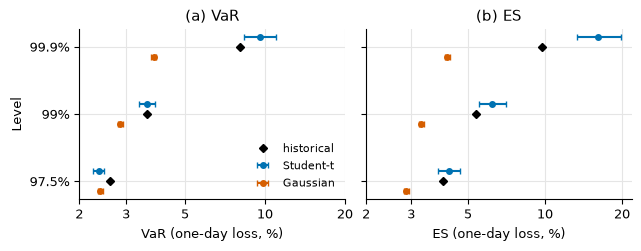

In [7]:
# Figure: VaR and ES of both models (posterior mean and 95% interval) against the historical values
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.4), sharey=True)
for ax, measure, title in zip(axes, ["VaR", "ES"], ["(a) VaR", "(b) ES"]):
    for row, alpha in enumerate(LEVELS):
        name = f"{measure} {100 * alpha:g}%"
        for offset, model, color in [(0.15, "Student-t", COLOR_T), (-0.15, "Gaussian", COLOR_GAUSS)]:
            s = posterior_risk.loc[(model, name)]
            ax.errorbar(s["mean"], row + offset, xerr=[[s["mean"] - s["2.5%"]], [s["97.5%"] - s["mean"]]],
                        fmt="o", color=color, markersize=4, capsize=2,
                        label=model if row == 0 else None)
        ax.plot(answers.loc[name, "historical"], row, "D", color="black", markersize=4,
                label="historical" if row == 0 else None)
    ax.set(xscale="log", xlabel=f"{measure} (one-day loss, %)", title=title)
    ax.set_xticks([2, 3, 5, 10, 20], labels=["2", "3", "5", "10", "20"])
    ax.minorticks_off()
axes[0].set(yticks=range(len(LEVELS)), yticklabels=[f"{100 * a:g}%" for a in LEVELS], ylabel="Level")
axes[0].legend(loc="lower right")
save_figure(fig, "risk.pdf")
plt.show()

**What we see.**
- **At 97.5%, the two models agree on the VaR.** The Student-t VaR is even slightly below the Gaussian one, because its density is more peaked in the centre, and both are a little below the historical VaR (notebook 06 counts the exceedances). The ES, the Basel measure at this level, is already 46% higher under the Student-t, and close to history.
- **From 99% on, the models part.** The Student-t 99% VaR, 3.60%, is 26% above the Gaussian and equal to the historical value; the 99% ES is 90% above the Gaussian. At 99.9%, the Student-t ES is about four times the Gaussian one: a Gaussian model would understate the average loss on the worst day in a thousand by a factor of four.
- **The tails, not parameter uncertainty, drive the gap.** Using the full posterior instead of a single best guess raises the answers by at most 1.5%. Parameter uncertainty shows up instead in the width of the intervals, which grows with the level: the 99.9% ES lies between 13% and 20%.
- **At 99.9%, the model is above history** (VaR 9.6% against 8.1%, ES 16% against 9.7%). History has only about five days beyond its 99.9% VaR, so its ES there rests on five numbers; the model extrapolates beyond them with its heavy tail, which notebook 04 suggested may be somewhat too heavy. Notebook 06 tests it.

### 3.1 How accurate are these numbers?

The predictive VaR and ES are computed from the 72,000 posterior draws, so they carry a Monte Carlo error. We measure it by batch means: we recompute them on each of the 40 batches of 1,800 draws.

In [8]:
# Monte Carlo standard errors (in % points) of the predictive Student-t VaR and ES, by batch means
rows = {}
for alpha in LEVELS:
    var_batches, es_batches = [], []
    for b in batches(theta_t):
        var_b, es_b = predictive_var_es(b, alpha, "student_t")
        var_batches.append(100 * var_b)
        es_batches.append(100 * es_b)
    for measure, values in [(f"VaR {100 * alpha:g}%", var_batches), (f"ES {100 * alpha:g}%", es_batches)]:
        rows[measure] = {"predictive value": answers.loc[measure, "Student-t predictive"],
                         "MCSE": batch_se(values)}
mcse = pd.DataFrame.from_dict(rows, orient="index")
mcse["MCSE of the interval ends"] = posterior_risk.loc["Student-t", "MCSE of the interval ends"].to_numpy()
mcse.index.name = "Measure (loss in %)"
save_table(mcse, "risk_mcse.tex", fmt="{:.3f}")
mcse.round(3)

,predictive value,MCSE,MCSE of the interval ends
Measure (loss in %),,,
VaR 97.5%,2.363,0.001,0.002
ES 97.5%,4.207,0.003,0.009
VaR 99%,3.599,0.002,0.005
ES 99%,6.238,0.005,0.016
VaR 99.9%,9.556,0.009,0.028
ES 99.9%,16.240,0.023,0.070


**What we see.** The Monte Carlo errors are at most 0.07 percentage points, on the ends of the 99.9% ES interval, and below 0.03 points for every predictive value: far smaller than the posterior uncertainty. Every digit we report is a property of the posterior, not of our simulation.

## 4. The rare event: plain Monte Carlo against importance sampling

How likely is a one-day loss beyond $x$? We estimate the predictive probability

$$p(x) = \Pr(\tilde L > x \mid y) = \mathbb{E}\big[\Pr(\tilde L > x \mid \theta) \,\big|\, y\big]$$

for $x$ = 5%, 10% and 20%. A 20% loss is worse than any day of our data and close to the crash of 19 October 1987: the model must extrapolate there. We compare three estimators, each with $N$ = 10,000 draws:

1. **Plain Monte Carlo** (the two-stage simulation): draw $\theta$ from the posterior, then a loss $\tilde L$ from the model, and count the losses beyond $x$. Its relative error is $\sqrt{(1-p)/(Np)}$: when $p$ is near $10^{-4}$, most runs see one event or none.
2. **Importance sampling:** draw the loss from a proposal $g$ that lives on the event, then weight it by $w = f_\theta(\tilde L)/g(\tilde L)$, with $f_\theta$ the density of the loss given $\theta$. The notes use a shifted exponential for a Gamma target. Our target has a **polynomial** tail, $f_\theta(L) \propto L^{-(\nu+1)}$, and an exponential proposal would have lighter tails than it: the weights would be unbounded and the variance infinite. We use a **Pareto** proposal on $(x, \infty)$, $g(L) = a\,x^a / L^{a+1}$ with $a = 2$, simulated by inverse transform, $\tilde L = x\,U^{-1/a}$. Since $a = 2 \le \nu$, the weights $w \propto L^{a-\nu}$ stay bounded.
3. **Rao–Blackwell:** average the exact tail probability $\Pr(\tilde L > x \mid \theta^{(i)})$ of each draw. This removes all the noise of simulating $\tilde L$, and leaves only the noise of drawing $\theta$.

The exact value of the target, for our posterior sample, is the Rao–Blackwell average over all 72,000 draws. Each estimator draws $\theta$ uniformly among those draws.

> **[COURSE]** Rare events and importance sampling: Ch. 3, Sec. 3.4.1 (p. 43); the importance sampling identity and its finite-variance condition: Proposition 3.2 (p. 44); a proposal with heavier tails than the target: App. B.3 (p. 86). Inverse transform: Ch. 2, Theorem 2.2 (p. 32). Rao–Blackwell: Proposition 3.4 (p. 47).

In [9]:
# All posterior draws of the Student-t model in one list, and the exact target of each threshold
theta_all = theta_t.reshape(-1, 3)

def simulate_losses(n_draws, rng):
    """Plain Monte Carlo: draw theta from the posterior, then one loss from the model with that theta."""
    theta = theta_all[rng.integers(0, len(theta_all), n_draws)]
    return -theta[:, 0] + theta[:, 1] * rng.standard_t(theta[:, 2])


def importance_sampling(x, n_draws, rng, index=PARETO_INDEX):
    """Importance sampling of the losses beyond x, with a Pareto(x, index) proposal.

    Returns the simulated losses (all beyond x) and their importance weights f / g: the mean of the
    weights estimates P(L > x), and the mean of the weights times the losses estimates E[L 1{L > x}].
    """
    theta = theta_all[rng.integers(0, len(theta_all), n_draws)]
    mu, sigma, nu = theta[:, 0], theta[:, 1], theta[:, 2]
    simulated = x * rng.uniform(size=n_draws) ** (-1 / index)  # inverse transform: L > x always
    log_f = stats.t.logpdf((simulated + mu) / sigma, nu) - np.log(sigma)  # density of the loss given theta
    log_g = np.log(index) + index * np.log(x) - (index + 1) * np.log(simulated)
    weights = np.exp(log_f - log_g)  # computed on the log scale
    return simulated, weights


def rao_blackwell(x, n_draws, rng):
    """Rao-Blackwell: the exact P(L > x | theta) and E[L 1{L > x} | theta] of n_draws posterior draws."""
    theta = theta_all[rng.integers(0, len(theta_all), n_draws)]
    return tail_t(theta, x)


exact = {x: tail_t(theta_all, x)[0].mean() for x in THRESHOLDS}
for x in THRESHOLDS:
    print(f"P(loss > {100 * x:.0f}% | y) = {exact[x]:.3e}: about one day in {1 / exact[x]:,.0f}; "
          f"in our {len(losses):,} days, {len(losses) * exact[x]:.1f} expected, {np.sum(losses > x)} observed")

P(loss > 5% | y) = 4.687e-03: about one day in 213; in our 5,031 days, 23.6 expected, 21 observed
P(loss > 10% | y) = 8.961e-04: about one day in 1,116; in our 5,031 days, 4.5 expected, 2 observed
P(loss > 20% | y) = 1.664e-04: about one day in 6,009; in our 5,031 days, 0.8 expected, 0 observed


In [10]:
# N_REPEATS runs of each estimator with N_DRAWS draws, for each threshold
estimates = {}
for x in THRESHOLDS:
    estimates[(x, "plain Monte Carlo")] = np.array([np.mean(simulate_losses(N_DRAWS, rng) > x)
                                                    for _ in range(N_REPEATS)])
    estimates[(x, "importance sampling")] = np.array([np.mean(importance_sampling(x, N_DRAWS, rng)[1])
                                                      for _ in range(N_REPEATS)])
    estimates[(x, "Rao-Blackwell")] = np.array([np.mean(rao_blackwell(x, N_DRAWS, rng)[0])
                                                for _ in range(N_REPEATS)])

# The variance study: bias, relative RMSE, runs that see no event, efficiency gain, draws needed
rows = []
for (x, name), est in estimates.items():
    p = exact[x]
    mse = np.mean((est - p) ** 2)
    per_draw_var = N_DRAWS * est.var()  # sigma_h^2: the variance of one draw's contribution
    rows.append({"loss beyond": f"{100 * x:.0f}%", "estimator": name, "exact p": p,
                 "mean of the estimates": est.mean(), "relative RMSE (%)": 100 * np.sqrt(mse) / p,
                 "runs estimating 0 (%)": 100 * np.mean(est == 0),
                 "draws for +-10% (95%)": (1.96 * np.sqrt(per_draw_var) / (0.1 * p)) ** 2})
study = pd.DataFrame(rows)
plain_mse = study[study["estimator"] == "plain Monte Carlo"].set_index("loss beyond")["relative RMSE (%)"] ** 2
study["efficiency gain"] = plain_mse[study["loss beyond"]].to_numpy() / study["relative RMSE (%)"] ** 2
for x in THRESHOLDS:
    observed = study[(study["loss beyond"] == f"{100 * x:.0f}%")
                     & (study["estimator"] == "plain Monte Carlo")]["relative RMSE (%)"].iloc[0]
    theory = 100 * np.sqrt((1 - exact[x]) / (N_DRAWS * exact[x]))
    print(f"plain Monte Carlo, loss beyond {100 * x:.0f}%: relative RMSE {observed:.1f}% observed, "
          f"{theory:.1f}% in theory, sqrt((1 - p) / (N p))")
study.set_index(["loss beyond", "estimator"])

plain Monte Carlo, loss beyond 5%: relative RMSE 14.0% observed, 14.6% in theory, sqrt((1 - p) / (N p))
plain Monte Carlo, loss beyond 10%: relative RMSE 33.6% observed, 33.4% in theory, sqrt((1 - p) / (N p))
plain Monte Carlo, loss beyond 20%: relative RMSE 75.5% observed, 77.5% in theory, sqrt((1 - p) / (N p))


exact p  mean of the estimates  \
loss beyond estimator                                              
5%          plain Monte Carlo    0.004687               0.004660   
            importance sampling  0.004687               0.004687   
            Rao-Blackwell        0.004687               0.004687   
10%         plain Monte Carlo    0.000896               0.000864   
            importance sampling  0.000896               0.000896   
            Rao-Blackwell        0.000896               0.000896   
20%         plain Monte Carlo    0.000166               0.000161   
            importance sampling  0.000166               0.000166   
            Rao-Blackwell        0.000166               0.000166   

                                 relative RMSE (%)  runs estimating 0 (%)  \
loss beyond estimator                                                       
5%          plain Monte Carlo            13.985627                    0.0   
            importance sampling           0.203270                    0.0   
            Rao-Blackwell                 0.105831                    0.0   
10%         plain Monte Carlo            33.577679                    0.0   
            importance sampling           0.252695                    0.0   
            Rao-Blackwell                 0.174495                    0.0   
20%         plain Monte Carlo            75.472073                   20.6   
            importance sampling           0.311934                    0.0   
            Rao-Blackwell                 0.261646                    0.0   

                                 draws for +-10% (95%)  efficiency gain  
loss beyond estimator                                                    
5%          plain Monte Carlo             7.501621e+04         1.000000  
            importance sampling           1.586711e+01      4733.904091  
            Rao-Blackwell                 4.293448e+00     17463.870479  
10%         plain Monte Carlo             4.281959e+05         1.000000  
            importance sampling           2.450698e+01     17656.620088  
            Rao-Blackwell                 1.167754e+01     37028.641755  
20%         plain Monte Carlo             2.183812e+06         1.000000  
            importance sampling           3.698724e+01     58539.271241  
            Rao-Blackwell                 2.627845e+01     83204.257351

> **[COURSE]** Variance of plain Monte Carlo, $\sigma_h^2/N$: Ch. 3, Sec. 3.2, Proposition 3.1 (p. 41); draws needed for a precision $\pm\varepsilon$, $N \ge (1.96\,\sigma_h/\varepsilon)^2$: Sec. 3.3.2, eq. (3.4) (p. 42). Effective sample size of the weights: Definition 3.3 (p. 45); checklist: App. B.5, item 4 (p. 87).

In [11]:
# Importance sampling diagnostics on one run per threshold: ESS of the weights and the largest weight
for x in THRESHOLDS:
    _, weights = importance_sampling(x, N_DRAWS, rng)
    normalized = weights / weights.sum()
    print(f"loss beyond {100 * x:.0f}%: ESS = {1 / np.sum(normalized ** 2):,.0f} of {N_DRAWS:,}, "
          f"largest normalized weight = {normalized.max():.5f} (equal weights: {1 / N_DRAWS:.5f})")

loss beyond 5%: ESS = 9,634 of 10,000, largest normalized weight = 0.00015 (equal weights: 0.00010)
loss beyond 10%: ESS = 9,394 of 10,000, largest normalized weight = 0.00019 (equal weights: 0.00010)
loss beyond 20%: ESS = 9,095 of 10,000, largest normalized weight = 0.00024 (equal weights: 0.00010)


In [12]:
# Table for the report
short = {"plain Monte Carlo": "plain MC", "importance sampling": "importance", "Rao-Blackwell": "Rao--Blackwell"}
labels = [f"{r['loss beyond']}, {short[r['estimator']]}" for _, r in study.iterrows()]
rare_report = pd.DataFrame({
    r"$p$ ($10^{-4}$)": [f"{1e4 * p:.2f}" for p in study["exact p"]],
    "Rel. RMSE (%)": [f"{v:.2f}" for v in study["relative RMSE (%)"]],
    "Runs at 0 (%)": [f"{v:.0f}" for v in study["runs estimating 0 (%)"]],
    "Gain": [f"{v:,.0f}" for v in study["efficiency gain"]],
    r"Draws for $\pm$10%": [f"{v:,.0f}" for v in study["draws for +-10% (95%)"]]},
    index=labels)
rare_report.index.name = "Loss beyond, estimator"
save_table(rare_report, "rare_event.tex")

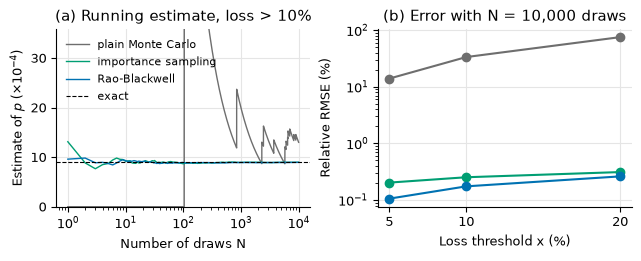

In [13]:
# Figure: (a) running estimates of p(10%) for one run of each estimator, (b) relative RMSE by threshold
colors = {"plain Monte Carlo": COLOR_DATA, "importance sampling": COLOR_OTHER, "Rao-Blackwell": COLOR_T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.3, 2.5))

x = 0.10
n_range = np.arange(1, N_DRAWS + 1)
theta = theta_all[rng.integers(0, len(theta_all), N_DRAWS)]
plain_hits = (-theta[:, 0] + theta[:, 1] * rng.standard_t(theta[:, 2])) > x
_, weights = importance_sampling(x, N_DRAWS, rng)
rb_terms = tail_t(theta, x)[0]
for name, terms in [("plain Monte Carlo", plain_hits), ("importance sampling", weights),
                    ("Rao-Blackwell", rb_terms)]:
    ax1.plot(n_range, 1e4 * np.cumsum(terms) / n_range, color=colors[name], linewidth=1, label=name)
ax1.axhline(1e4 * exact[x], color="black", linestyle="--", linewidth=0.8, label="exact")
ax1.set(xscale="log", ylim=(0, 4 * 1e4 * exact[x]), xlabel="Number of draws N",
        ylabel=r"Estimate of $p$ ($\times 10^{-4}$)", title="(a) Running estimate, loss > 10%")
ax1.legend(loc="upper left")

for name in colors:
    sub = study[study["estimator"] == name]
    ax2.plot(100 * np.array(THRESHOLDS), sub["relative RMSE (%)"], "o-", color=colors[name], label=name)
ax2.set(yscale="log", xlabel="Loss threshold x (%)", ylabel="Relative RMSE (%)",
        title=f"(b) Error with N = {N_DRAWS:,} draws", xticks=100 * np.array(THRESHOLDS))
save_figure(fig, "rare_event.pdf")
plt.show()

**What we see.**
- **Plain Monte Carlo fails on rare losses.** With 10,000 draws, its relative error grows from 14% (loss beyond 5%) to 75% (beyond 20%), as the theory $\sqrt{(1-p)/(Np)}$ predicts, and one run in five sees no loss beyond 20% at all and reports a probability of zero. Panel (a) shows why: the running estimate stays at zero, then jumps at each rare hit. To know $p(20\%)$ within ±10%, it would need about two million draws.
- **Importance sampling fixes it.** Every proposal lands in the tail, and the weights correct for it: the relative error drops to 0.2–0.3%, an efficiency gain of about 5,000 to 60,000, and a few dozen draws are enough for ±10%. The weights are well behaved (an ESS above 9,000 of 10,000, no dominant weight), because the Pareto proposal follows the shape of the Student-t tail.
- **Rao–Blackwell is slightly better still,** because the tail probability given $\theta$ has a closed form here: no loss needs to be simulated, and only the uncertainty about $\theta$ remains (the law of total variance of Proposition 3.4). Importance sampling is the general tool, needed as soon as this conditional probability has no formula (a portfolio of several assets, for instance); Rao–Blackwell is what we use for the predictive VaR and ES.
- **The answer:** under our model, a one-day loss beyond 10% has a probability of about 9 in 10,000, once every four to five years, and a crash beyond 20% about 1.7 in 10,000, once in about 24 years. Our 20 years contain about as many losses beyond 5% as the model expects (21 against 24), but fewer beyond 10% (2 against 4.5). At such small counts this is not significant on its own (a Poisson count of mean 4.5 is 2 or less about once in six), but it points in the same direction as notebook 04: the model's far tail may be somewhat too heavy.

### 4.1 The 99.9% Expected Shortfall

The ES is harder to estimate than a probability. With $v$ the predictive 99.9% VaR, it is a tail mean,

$$\text{ES}_{0.999} = \frac{\mathbb{E}\big[\tilde L\,\mathbf 1\{\tilde L > v\} \mid y\big]}{1 - 0.999},$$

and the function $h(L) = L\,\mathbf 1\{L > v\}$ is now unbounded. We fix $v$ at its exact value and compare four estimators of the tail mean, each with $N$ = 10,000 draws, repeated 500 times:

1. **Plain Monte Carlo:** the average of $\tilde L\,\mathbf 1\{\tilde L > v\}$ over simulated losses; only about 10 draws in 10,000 fall in the tail. With $\nu$ near 2.5, $h$ has a finite variance (it needs $\nu > 2$) but not a finite fourth moment, so the *estimated* standard error of each run should itself be erratic.
2. **Importance sampling with our Pareto proposal**, $a = 2$, now averaging $w(\tilde L)\,\tilde L$.
3. **Importance sampling with $a = 1.5$.** The best proposal is proportional to $|h|\,f$. Beyond $v$, $|h(L)|\,f_\theta(L) \propto L \cdot L^{-(\nu+1)} = L^{-\nu}$: a Pareto of index $\nu - 1 \approx 1.5$. The variance stays finite when $a < 2\nu - 2$, which holds for both proposals whenever $\nu > 2$.
4. **Rao–Blackwell:** the exact $\mathbb{E}[\tilde L\,\mathbf 1\{\tilde L > v\} \mid \theta]$, averaged. Over all 72,000 draws, it gives the exact target, our ES of section 2.

For each estimator, we compare the spread of its 500 estimates (its true standard error) with the standard error that each run estimates from its own draws.

> **[COURSE]** The optimal proposal, $g^\star \propto |h|\,f$: Ch. 3, Sec. 3.4.2, Proposition 3.3 (p. 44); finite variance: Proposition 3.2 (p. 44). When the CLT fails, the standard error cannot be trusted: Sec. 3.3.3, Remark 3.1 (p. 43).

In [14]:
# Target: the tail mean beyond the predictive 99.9% VaR; over all the draws, it gives our ES exactly
ALPHA = 0.999
v = predictive_var_es(theta_t, ALPHA)[0]
exact_tail = tail_t(theta_all, v)[1].mean()
print(f"99.9% VaR v = {100 * v:.2f}%; exact tail mean = {exact_tail:.3e}, "
      f"so ES = {100 * exact_tail / (1 - ALPHA):.2f}%")

# N_REPEATS runs of four estimators of the tail mean: each run gives an estimate and its estimated SE
es_estimators = ["plain Monte Carlo", "importance sampling, a = 2", "importance sampling, a = 1.5",
                 "Rao-Blackwell"]
es_runs = {name: [] for name in es_estimators}
for _ in range(N_REPEATS):
    simulated = simulate_losses(N_DRAWS, rng)
    terms = {"plain Monte Carlo": simulated * (simulated > v)}
    for index in [2.0, 1.5]:
        simulated_is, weights = importance_sampling(v, N_DRAWS, rng, index)
        terms[f"importance sampling, a = {index:g}"] = weights * simulated_is
    terms["Rao-Blackwell"] = rao_blackwell(v, N_DRAWS, rng)[1]
    for name, values in terms.items():
        es_runs[name].append([values.mean(), values.std(ddof=1) / np.sqrt(N_DRAWS)])

99.9% VaR v = 9.56%; exact tail mean = 1.624e-04, so ES = 16.24%


In [15]:
# The variance study of the ES: accuracy, efficiency, and how far each run's own standard error can be trusted
rows = {}
for name in es_estimators:
    runs = np.array(es_runs[name])  # one row per run: estimate, estimated standard error
    estimates_es = runs[:, 0]
    true_se = estimates_es.std(ddof=1)  # the actual spread of the estimates over the runs
    se_ratio = runs[:, 1] / true_se     # estimated / actual standard error, run by run
    rows[name] = {"ES (%)": 100 * estimates_es.mean() / (1 - ALPHA),
                  "relative RMSE (%)": 100 * np.sqrt(np.mean((estimates_es - exact_tail) ** 2)) / exact_tail,
                  "estimated / true SE, 5%": np.quantile(se_ratio, 0.05),
                  "estimated / true SE, 95%": np.quantile(se_ratio, 0.95)}
es_study = pd.DataFrame.from_dict(rows, orient="index")
plain_rmse = es_study.loc["plain Monte Carlo", "relative RMSE (%)"]
es_study["efficiency gain"] = (plain_rmse / es_study["relative RMSE (%)"]) ** 2
es_study.round(3)

,ES (%),relative RMSE (%),"estimated / true SE, 5%","estimated / true SE, 95%",efficiency gain
plain Monte Carlo,16.523,39.661,0.527,1.589,1.000
"importance sampling, a = 2",16.244,0.531,0.877,1.201,5577.911
"importance sampling, a = 1.5",16.241,0.235,0.949,1.016,28468.402
Rao-Blackwell,16.242,0.197,1.031,1.058,40593.289


In [16]:
# Table for the report
es_report = pd.DataFrame({
    "ES (%)": [f"{v_:.2f}" for v_ in es_study["ES (%)"]],
    "Rel. RMSE (%)": [f"{v_:.2f}" for v_ in es_study["relative RMSE (%)"]],
    "Gain": [f"{v_:,.0f}" for v_ in es_study["efficiency gain"]],
    "Estimated / true SE, 5%--95%": [f"[{a_:.2f}, {b_:.2f}]" for a_, b_ in
                                     zip(es_study["estimated / true SE, 5%"], es_study["estimated / true SE, 95%"])]},
    index=["Plain Monte Carlo", r"Importance sampling, $a = 2$", r"Importance sampling, $a = 1.5$",
           "Rao--Blackwell"])
es_report.index.name = "Estimator"
save_table(es_report, "rare_es.tex")

**What we see.**
- **All four estimators reproduce our ES of 16.24% on average**: an independent, simulation-based check of the closed-form computation of section 2.
- **Plain Monte Carlo is unreliable twice over.** Its error is about 40% with 10,000 draws, and its own estimate of that error is erratic: from one run to the next, it ranges from about half to one and a half times the true standard error. With $\nu$ near 2.5, the losses beyond the VaR have no finite fourth moment, which is exactly the warning of Remark 3.1.
- **Importance sampling fixes both.** With our proposal ($a = 2$), the error falls to 0.5%, a gain of about 5,600, and the estimated standard errors become reliable.
- **The near-optimal proposal ($a = 1.5$) does five times better still**: an error of 0.24%, a gain of about 28,000, and standard errors that can be trusted almost exactly. As Proposition 3.3 predicts, the closer $g$ is to $|h|\,f$, the flatter the terms $w\,h$, so the right proposal depends on what we estimate. Rao–Blackwell remains the most precise, since the conditional tail mean has a closed form.

## 5. What we found

In [17]:
# Numbers quoted in the report
for measure in answers.index:
    a = answers.loc[measure]
    s = posterior_risk.loc[("Student-t", measure)]
    print(f"{measure:>9}: Student-t {a['Student-t predictive']:6.2f}% [{s['2.5%']:.2f}, {s['97.5%']:.2f}], "
          f"Gaussian {a['Gaussian predictive']:5.2f}%, historical {a['historical']:5.2f}%, "
          f"tail effect {a['tail effect (%)']:+4.0f}%, uncertainty effect {a['uncertainty effect (%)']:+.1f}%, "
          f"ratio {a['Student-t / Gaussian']:.1f}, Gaussian understates by "
          f"{100 * (1 - a['Gaussian predictive'] / a['Student-t predictive']):.0f}%")
print(f"Largest Monte Carlo error: {mcse[['MCSE', 'MCSE of the interval ends']].max().max():.3f} % points")
for x in THRESHOLDS:
    sub = study[study["loss beyond"] == f"{100 * x:.0f}%"].set_index("estimator")
    print(f"Loss beyond {100 * x:.0f}%: p = {exact[x]:.2e}; relative RMSE plain "
          f"{sub.loc['plain Monte Carlo', 'relative RMSE (%)']:.1f}%, importance sampling "
          f"{sub.loc['importance sampling', 'relative RMSE (%)']:.2f}%, Rao-Blackwell "
          f"{sub.loc['Rao-Blackwell', 'relative RMSE (%)']:.2f}%; plain runs at 0: "
          f"{sub.loc['plain Monte Carlo', 'runs estimating 0 (%)']:.0f}%")
for name, r in es_study.iterrows():
    print(f"99.9% ES, {name:>29}: {r['ES (%)']:.2f}%, relative RMSE {r['relative RMSE (%)']:.2f}%, "
          f"gain {r['efficiency gain']:,.0f}, estimated / true SE in "
          f"[{r['estimated / true SE, 5%']:.2f}, {r['estimated / true SE, 95%']:.2f}]")

VaR 97.5%: Student-t   2.36% [2.25, 2.48], Gaussian  2.40%, historical  2.62%, tail effect   -2%, uncertainty effect +0.2%, ratio 1.0, Gaussian understates by -2%
 ES 97.5%: Student-t   4.21% [3.84, 4.64], Gaussian  2.87%, historical  4.00%, tail effect  +46%, uncertainty effect +0.5%, ratio 1.5, Gaussian understates by 32%
  VaR 99%: Student-t   3.60% [3.36, 3.87], Gaussian  2.86%, historical  3.60%, tail effect  +26%, uncertainty effect +0.2%, ratio 1.3, Gaussian understates by 21%
   ES 99%: Student-t   6.24% [5.54, 7.07], Gaussian  3.28%, historical  5.39%, tail effect  +90%, uncertainty effect +0.7%, ratio 1.9, Gaussian understates by 47%
VaR 99.9%: Student-t   9.56% [8.32, 11.02], Gaussian  3.81%, historical  8.09%, tail effect +151%, uncertainty effect +0.7%, ratio 2.5, Gaussian understates by 60%
 ES 99.9%: Student-t  16.24% [13.32, 19.79], Gaussian  4.16%, historical  9.70%, tail effect +291%, uncertainty effect +1.5%, ratio 3.9, Gaussian understates by 74%
Largest Monte Carlo

- **The answer to our question.** Over 2006–2025, a one-day loss of the US stock market above 3.60% happens on about 1 trading day in 100 (95% interval [3.36%, 3.87%]), and the average loss on those days is about 6.2%. A Gaussian model understates them by 21% and 47%, and the 99.9% ES by 74%, a factor of four.
- **Heavy tails, not parameter uncertainty, make the difference:** parameter uncertainty adds at most 1.5% to the predictive answers, and mostly widens the intervals.
- **Rare losses need the right Monte Carlo method:** plain Monte Carlo misses them; importance sampling with a heavy-tailed Pareto proposal is thousands of times more efficient; Rao–Blackwellization, available here thanks to a closed form, is better still.
- **The same holds for the 99.9% ES,** which simulation confirms at 16.24%: plain Monte Carlo errs by about 40% and cannot even estimate its own error, while importance sampling with a proposal close to the optimal $|h|\,f$ reaches 0.24%.
- **To check:** at 99.9% the model is well above history, and it expects slightly more losses beyond 10% than we observed.

**Next:** `06_checks.ipynb` checks the fit with posterior predictive simulations and the VaR exceedances, tests the sensitivity to the priors and the window, and cross-checks the posterior by importance sampling.